# Q2a — CNN on CIFAR-10 (self-contained notebook)

## Purpose
This notebook contains the complete Q2a workflow in one file. All code is copied into cells from the original scripts; the notebook does **not** import from `common.py`, `q2_cnn.py`, `q2_random_search.py`, or `reproduce_confusion.py`.

## How to run
- **Default:** all three training switches in Section 1 are `False`. The notebook loads and displays the artifacts already saved in `results/`, so it runs quickly and performs no training.
- **To retrain:** set any switch to `True` and run all cells. Every file generated by this notebook then goes only to `results_nb/`; `results/` is never written by the notebook.
- **Kernel:** use the project `.venv` (Python 3 with TensorFlow/Keras).

## Switches
| Switch | What it reruns |
|---|---|
| `RUN_BASE_EXPERIMENT` | The four base configurations (baseline, dropout, augmentation, dropout+aug) |
| `RUN_RANDOM_SEARCH` | The random-search extension with early stopping |
| `RUN_CONFUSION_REPRO` | Baseline and best-tuned retraining for the exact confusion analysis |

All numbers shown below are either read from the saved JSON/NumPy artifacts or computed from the CIFAR-10 data in this notebook.


## 1. Setup

Paths are resolved relative to this notebook, so the notebook works when opened from `Q2a/` or executed from the repository root. The three switches below are the only things you need to edit to enable retraining.


In [1]:
import json
import os
from io import BytesIO
from pathlib import Path

import numpy as np
from IPython.display import Image, Markdown, display
from sklearn.metrics import classification_report

# ----------------------------------------------------------------------------
# Training switches - all False by default.
# Set any to True to rerun that part. All generated files then go to results_nb/.
# ----------------------------------------------------------------------------
RUN_BASE_EXPERIMENT = False
RUN_RANDOM_SEARCH = False
RUN_CONFUSION_REPRO = False

ANY_TRAINING = RUN_BASE_EXPERIMENT or RUN_RANDOM_SEARCH or RUN_CONFUSION_REPRO

# Hyperparameters copied from the original scripts.
EPOCHS_BASE = 40
BATCH_BASE = 64
N_TRIALS = 12
EPOCHS_TUNED = 30

CONFIGS = {
    "baseline":      dict(dropout=0.0, augment=False),
    "dropout":       dict(dropout=0.4, augment=False),
    "augmentation":  dict(dropout=0.0, augment=True),
    "dropout+aug":   dict(dropout=0.4, augment=True),
}


def _candidate_dirs():
    """Directories to search for the notebook / project artifacts."""
    cwd = Path.cwd().resolve()
    candidates = [cwd]
    candidates.extend(cwd.parents)

    # Hosted runtimes expose the notebook path or upload directory via env vars.
    for env_name in ("Q2A_PROJECT_DIR", "JPY_SESSION_NAME", "JPY_WORKDIR",
                     "NOTEBOOK_PATH", "COLAB_NOTEBOOK_PATH"):
        value = os.environ.get(env_name)
        if not value:
            continue
        path = Path(value).expanduser().resolve()
        candidates.append(path if path.is_dir() else path.parent)

    # Common upload / mount locations in hosted kernels.
    for mount in ("/mnt/data", "/content", "/kaggle/input"):
        candidates.append(Path(mount).resolve())

    seen = set()
    for directory in candidates:
        key = str(directory)
        if key not in seen:
            seen.add(key)
            yield directory


def _notebook_dir():
    """Find the folder containing Q2a_CNN.ipynb, or its parent containing Q2a/."""
    checked = []
    for directory in _candidate_dirs():
        checked.append(directory)
        if (directory / "Q2a_CNN.ipynb").is_file():
            return directory
        if (directory / "Q2a" / "Q2a_CNN.ipynb").is_file():
            return (directory / "Q2a").resolve()
        # Also works if the notebook was renamed but results/ came with it.
        if (directory / "results" / "results.json").is_file():
            return directory
        if (directory / "Q2a" / "results" / "results.json").is_file():
            return (directory / "Q2a").resolve()

    searched = "\n  ".join(str(directory) for directory in checked)
    raise RuntimeError(
        "Could not find Q2a_CNN.ipynb or results/results.json. "
        "In a hosted runtime, set the environment variable Q2A_PROJECT_DIR to the "
        "folder containing Q2a_CNN.ipynb, or to its parent folder containing Q2a/. "
        "Searched:\n  " + searched
    )


NB_DIR = _notebook_dir()
RESULTS = NB_DIR / "results"
RESULTS_NB = NB_DIR / "results_nb"
OUTPUT_DIR = RESULTS_NB if ANY_TRAINING else RESULTS

if ANY_TRAINING:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def artifact_path(name):
    """Prefer a notebook-generated artifact; otherwise fall back to results/."""
    preferred = OUTPUT_DIR / name
    if preferred.exists():
        return preferred
    fallback = RESULTS / name
    if fallback.exists():
        return fallback
    return preferred


def read_json(name):
    return json.loads(artifact_path(name).read_text(encoding="utf-8"))


def show_image(name, caption=None):
    path = artifact_path(name)
    if path.is_file():
        if caption:
            print(caption)
        display(Image(filename=str(path)))
    else:
        print(f"[not found] {path}")


def show_figure(fig):
    buf = BytesIO()
    fig.savefig(buf, format="png", dpi=120)
    plt.close(fig)
    display(Image(buf.getvalue()))


print("notebook dir:", NB_DIR)
print("results dir: ", RESULTS)
print("output dir:  ", OUTPUT_DIR)
print("switches: base=%s random=%s confusion=%s"
      % (RUN_BASE_EXPERIMENT, RUN_RANDOM_SEARCH, RUN_CONFUSION_REPRO))


notebook dir: D:\work\Machine Learning\Q2a
results dir:  D:\work\Machine Learning\Q2a\results
output dir:   D:\work\Machine Learning\Q2a\results
switches: base=False random=False confusion=False


## 2. Utilities

The functions below are copied verbatim from `common.py`. The constant `RESULTS_DIR` is kept for fidelity, but the notebook uses the `Path` objects defined above for all file access.


In [2]:
"""Shared utilities for Q2a (CNN image classification on CIFAR-10)."""
import json
import os

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
RESULTS_DIR = "results"
CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]


def set_seed(seed=SEED):
    keras.utils.set_random_seed(seed)


def load_data(n_train=10000, n_val=5000):
    """CIFAR-10 with a small training subset so overfitting is easy to observe.
    Train / val are disjoint subsets of the official train set; test = official test set."""
    (x, y), (x_te, y_te) = keras.datasets.cifar10.load_data()
    y, y_te = y.ravel(), y_te.ravel()
    idx = np.random.default_rng(SEED).permutation(len(x))
    val_idx, tr_idx = idx[:n_val], idx[n_val:n_val + n_train]
    f = lambda a: a.astype("float32") / 255.0
    return {"x_train": f(x[tr_idx]), "y_train": y[tr_idx],
            "x_val": f(x[val_idx]), "y_val": y[val_idx],
            "x_test": f(x_te), "y_test": y_te}


def build_cnn(dropout=0.0, augment=False, filters=(32, 64, 128),
              dense_units=256, lr=1e-3):
    """VGG-style CNN: [Conv-Conv-MaxPool(-Dropout)] x len(filters) -> Flatten -> Dense -> Softmax.
    - augment: random flip / translation / rotation layers (active only during training)
    - dropout: p after the Dense layer, p/2 after each pooling block (0 = disabled)
    """
    inputs = keras.Input(shape=(32, 32, 3))
    x = inputs
    if augment:
        x = layers.RandomFlip("horizontal")(x)
        x = layers.RandomTranslation(0.1, 0.1)(x)
        x = layers.RandomRotation(0.05)(x)
    for f in filters:
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D(2)(x)
        if dropout > 0:
            x = layers.Dropout(dropout / 2)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(dense_units, activation="relu")(x)
    if dropout > 0:
        x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


def fit(model, data, epochs, batch_size, callbacks=None):
    return model.fit(data["x_train"], data["y_train"],
                     validation_data=(data["x_val"], data["y_val"]),
                     epochs=epochs, batch_size=batch_size,
                     callbacks=callbacks or [], verbose=2)


def evaluate_test(model, data):
    loss, acc = model.evaluate(data["x_test"], data["y_test"], verbose=0)
    y_pred = model.predict(data["x_test"], verbose=0).argmax(axis=1)
    return {"test_loss": float(loss), "test_acc": float(acc)}, y_pred


def summarize_history(hist):
    """Key numbers for the report: final train/val acc, generalization gap, best val epoch."""
    h = hist.history
    best = int(np.argmax(h["val_accuracy"]))
    return {"epochs_run": len(h["loss"]),
            "final_train_acc": float(h["accuracy"][-1]),
            "final_val_acc": float(h["val_accuracy"][-1]),
            "final_train_loss": float(h["loss"][-1]),
            "final_val_loss": float(h["val_loss"][-1]),
            "acc_gap_train_minus_val": float(h["accuracy"][-1] - h["val_accuracy"][-1]),
            "best_val_acc": float(h["val_accuracy"][best]),
            "best_val_epoch": best + 1}


def plot_curves(histories, path):
    """histories: {name: history_dict}. Left = loss, right = accuracy (solid=train, dashed=val)."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for i, (name, h) in enumerate(histories.items()):
        c = f"C{i}"
        axes[0].plot(h["loss"], c=c, label=f"{name} (train)")
        axes[0].plot(h["val_loss"], c=c, ls="--", label=f"{name} (val)")
        axes[1].plot(h["accuracy"], c=c, label=f"{name} (train)")
        axes[1].plot(h["val_accuracy"], c=c, ls="--", label=f"{name} (val)")
    for ax, t in zip(axes, ["Loss", "Accuracy"]):
        ax.set_title(t); ax.set_xlabel("Epoch"); ax.grid(alpha=.3)
    axes[0].legend(fontsize=7)
    fig.tight_layout(); fig.savefig(path, dpi=150); plt.close(fig)


def plot_confusion(y_true, y_pred, title, path):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
        ax=ax, xticks_rotation=45, colorbar=False)
    ax.set_title(title)
    fig.tight_layout(); fig.savefig(path, dpi=150); plt.close(fig)


def save_json(obj, path):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False)


## 3. Data and sample grid

The split is the one from `common.py`: a small training subset and a disjoint validation subset drawn from the official CIFAR-10 train set, with the official test set untouched. The code below prints the resulting shapes, and the sample grid is drawn from the training subset with a fixed generator.


{'x_train': (10000, 32, 32, 3), 'y_train': (10000,), 'x_val': (5000, 32, 32, 3), 'y_val': (5000,), 'x_test': (10000, 32, 32, 3), 'y_test': (10000,)}


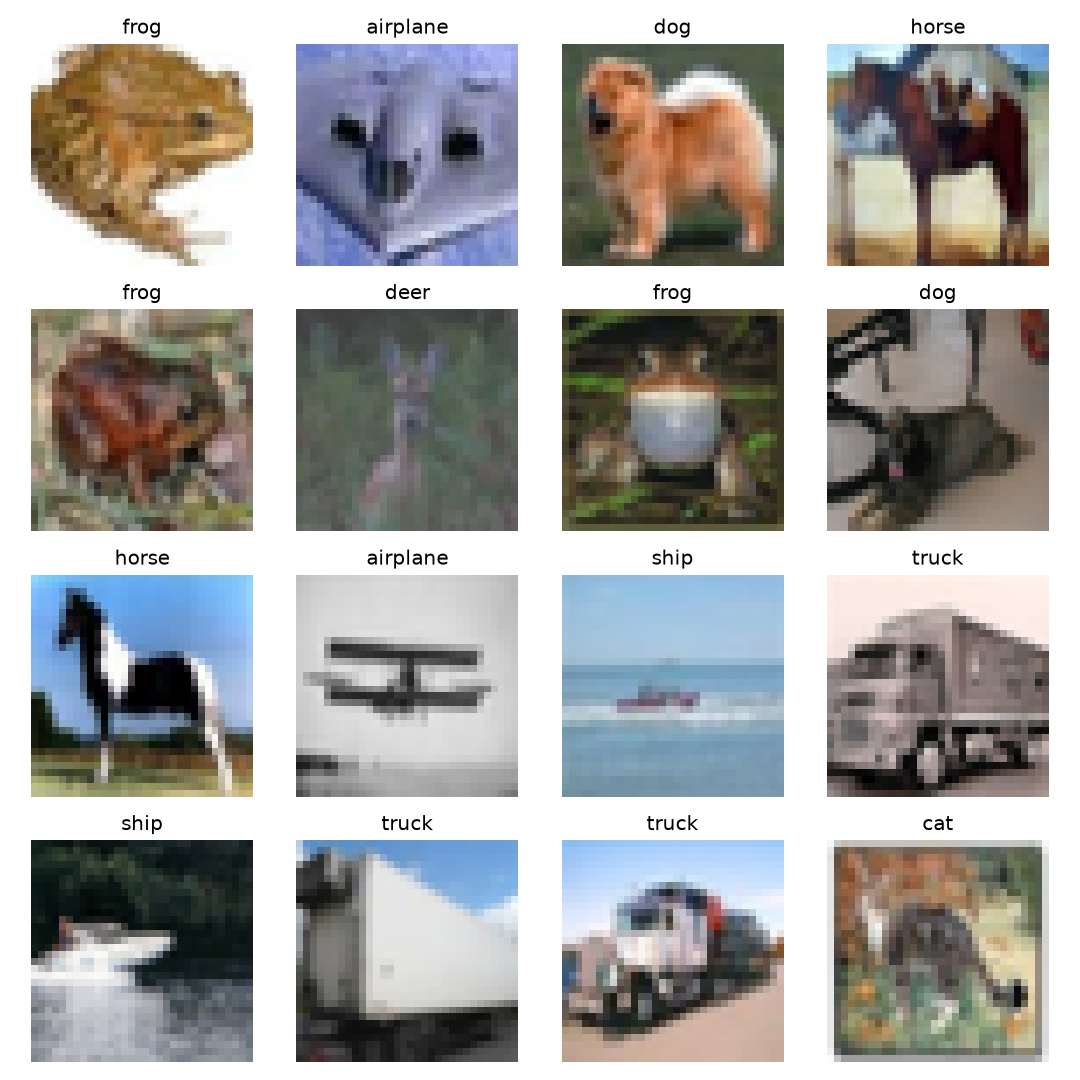

In [3]:
data = load_data()
print({k: tuple(v.shape) for k, v in data.items()})

rng_show = np.random.default_rng(SEED)
idx_show = rng_show.choice(len(data["y_train"]), size=16, replace=False)
fig, axes = plt.subplots(4, 4, figsize=(9, 9))
for ax, i in zip(axes.ravel(), idx_show):
    ax.imshow(data["x_train"][i])
    ax.set_title(CLASS_NAMES[int(data["y_train"][i])])
    ax.axis("off")
fig.tight_layout()
show_figure(fig)


## 4. Base model summary and parameter count

The baseline architecture is instantiated with the original seed and settings. No training is performed in this section.


In [4]:
set_seed()
base_model = build_cnn(**CONFIGS["baseline"])
base_model.summary()
print("trainable parameters:", int(base_model.count_params()))


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 814,122 (3.11 MB)

 Trainable params: 814,122 (3.11 MB)

 Non-trainable params: 0 (0.00 B)

trainable parameters: 814122


## 5. Experiment 1 — baseline vs. dropout vs. augmentation vs. both

With `RUN_BASE_EXPERIMENT = False`, the table and figures come from the saved `results/` artifacts. Setting the switch to `True` retrains all four configurations and writes only to `results_nb/`. The configuration dictionary, seed, epochs, batch size, optimizer, and callbacks are copied from the original experiment script.


In [5]:
def run_base_experiment(dataset, outdir):
    outdir = Path(outdir)
    outdir.mkdir(parents=True, exist_ok=True)
    results, histories = {}, {}

    for name, cfg in CONFIGS.items():
        print(f"\n===== {name} {cfg} =====")
        set_seed()                                   # same init seed for every config
        model = build_cnn(**cfg)
        if name == "baseline":
            model.summary()
        hist = fit(model, dataset, EPOCHS_BASE, BATCH_BASE)
        test_metrics, y_pred = evaluate_test(model, dataset)
        results[name] = {**cfg, **summarize_history(hist), **test_metrics,
                         "n_params": int(model.count_params())}
        histories[name] = hist.history
        plot_confusion(dataset["y_test"], y_pred, f"Confusion matrix - {name}",
                       str(outdir / f"confusion_{name.replace('+', '_')}.png"))
        print(classification_report(dataset["y_test"], y_pred,
                                    target_names=CLASS_NAMES, digits=3))
        print(results[name])

    plot_curves(histories, str(outdir / "curves_all.png"))
    for name, h in histories.items():
        plot_curves({name: h}, str(outdir / f"curves_{name.replace('+', '_')}.png"))
    save_json(results, str(outdir / "results.json"))
    return results



config             train       val       gap      TEST
baseline          0.9861    0.5838    0.4023    0.5833
dropout           0.9128    0.6620    0.2508    0.6766
augmentation      0.8249    0.6848    0.1401    0.6888
dropout+aug       0.7112    0.6616    0.0496    0.6697
Training curves (all configurations)


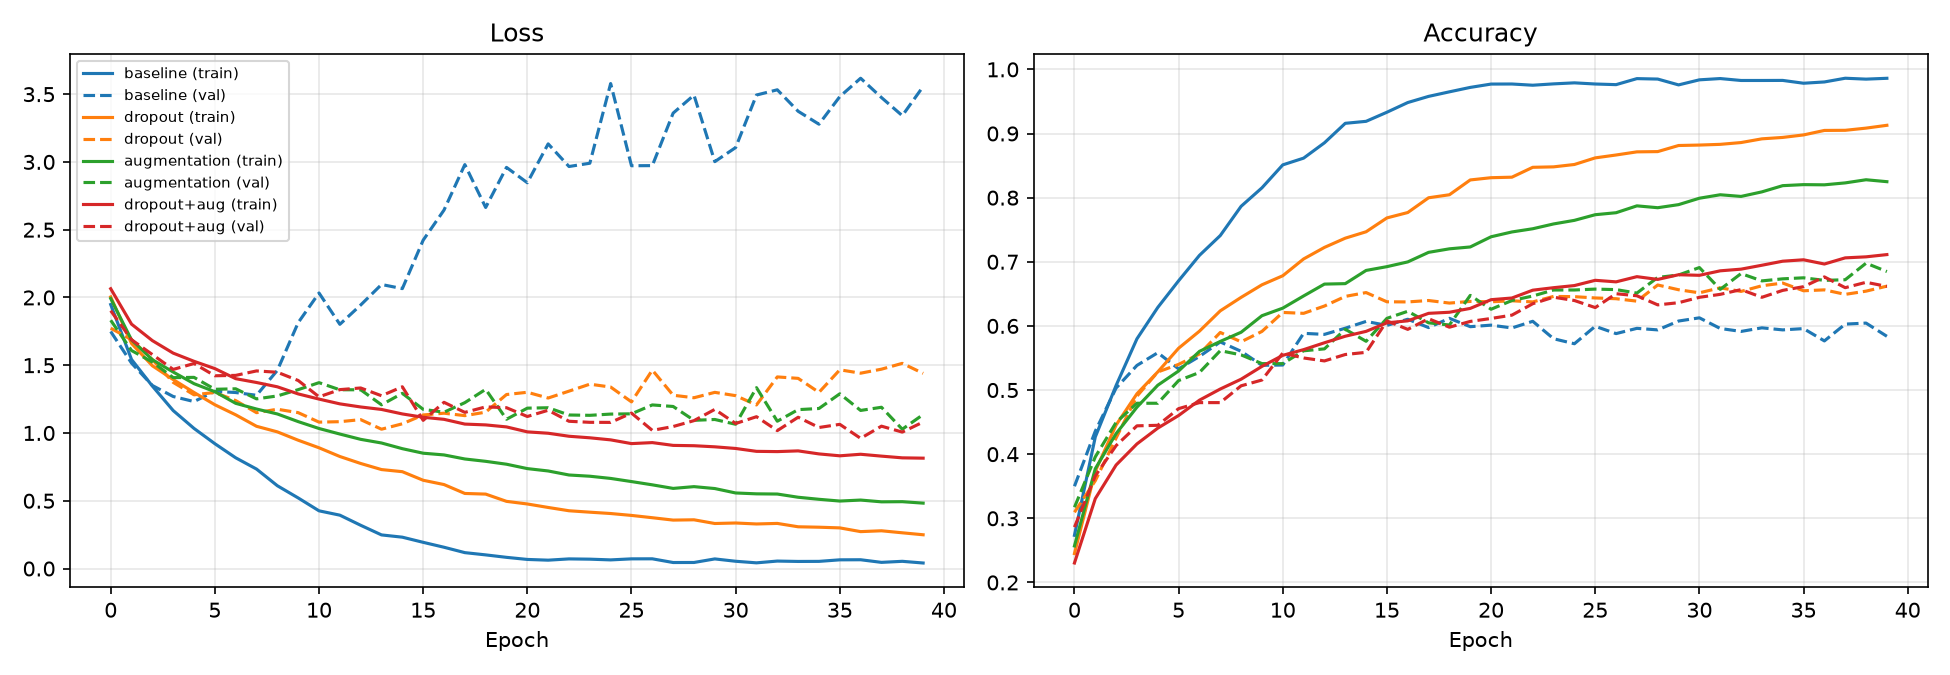

Confusion matrix - baseline


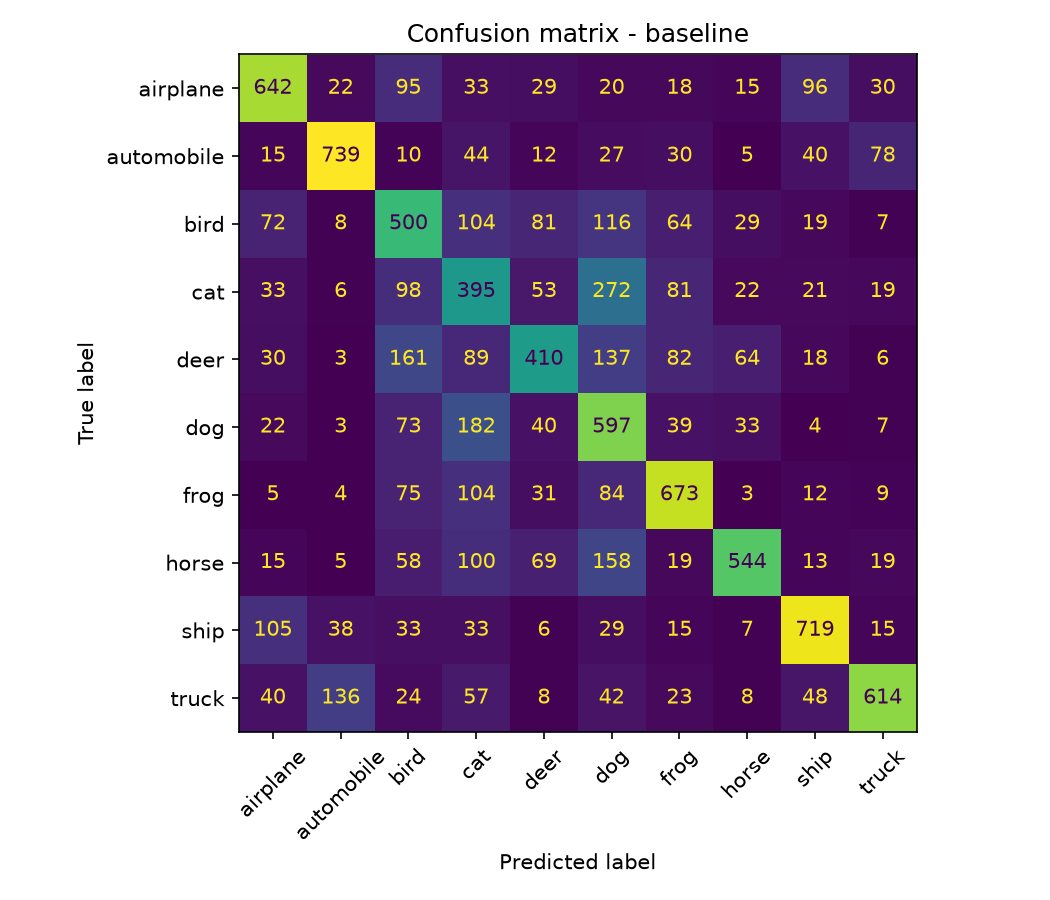

Confusion matrix - dropout


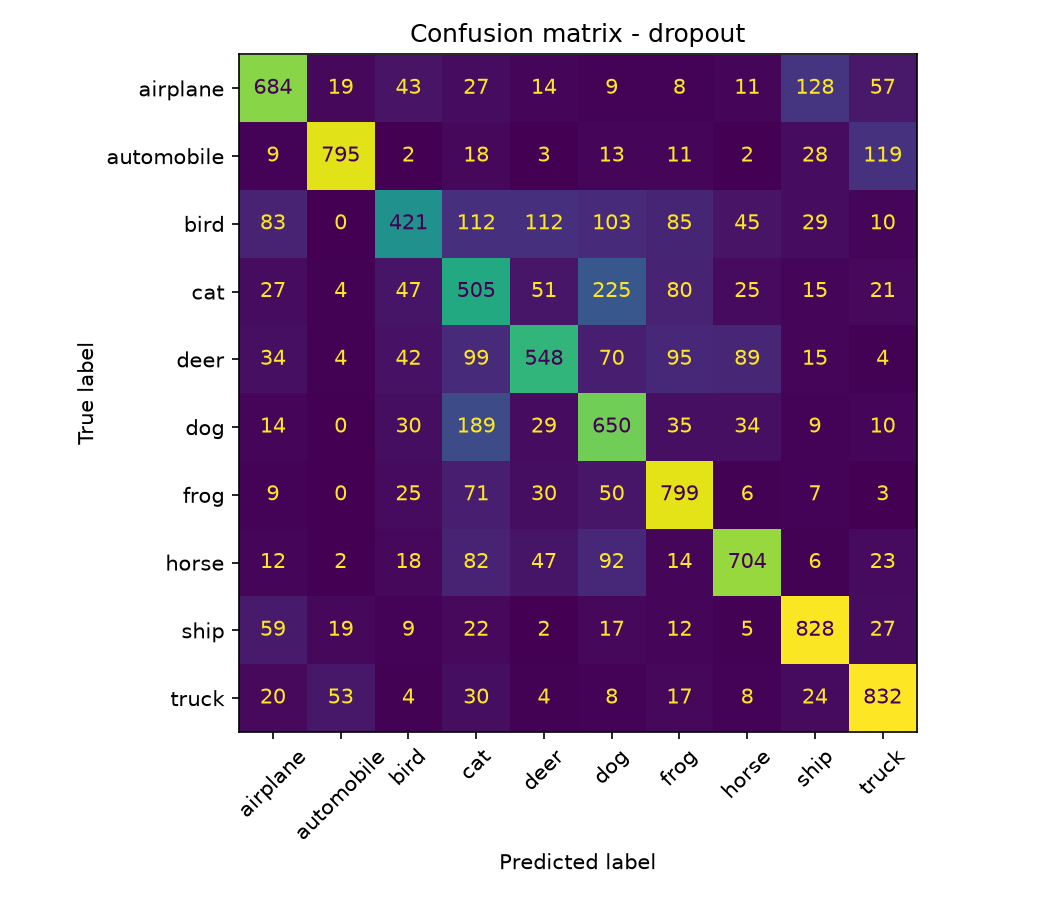

Confusion matrix - augmentation


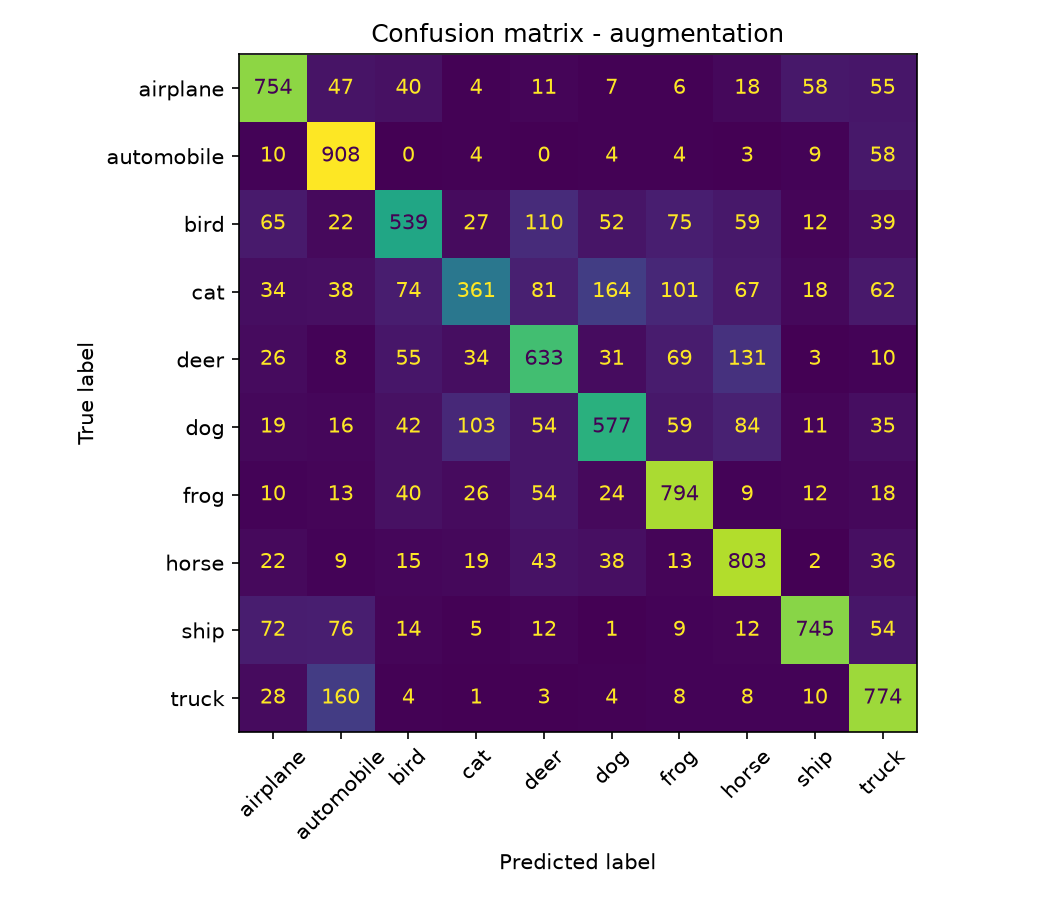

Confusion matrix - dropout+aug


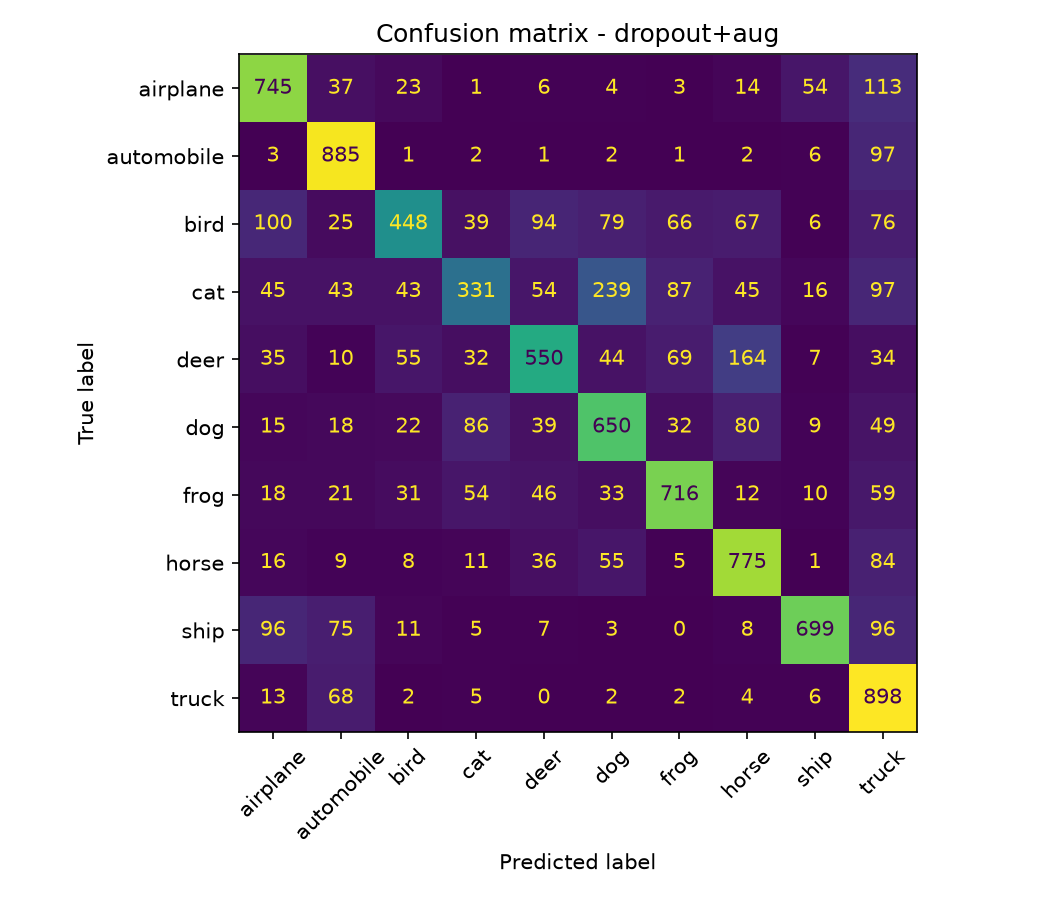

In [6]:
if RUN_BASE_EXPERIMENT:
    base_results = run_base_experiment(data, RESULTS_NB)
else:
    base_results = read_json("results.json")

print("\n%-14s %9s %9s %9s %9s" % ("config", "train", "val", "gap", "TEST"))
for n, r in base_results.items():
    print("%-14s %9.4f %9.4f %9.4f %9.4f"
          % (n, r["final_train_acc"], r["final_val_acc"],
             r["acc_gap_train_minus_val"], r["test_acc"]))

show_image("curves_all.png", "Training curves (all configurations)")
for name in CONFIGS:
    show_image(f"confusion_{name.replace('+', '_')}.png", f"Confusion matrix - {name}")


## 6. Confusion analysis — baseline vs. best tuned model

The analysis functions are adapted from `reproduce_confusion.py` and operate on saved test predictions, so the default path computes per-class accuracy and confused class pairs directly from `results/exact/*.npy`. With `RUN_CONFUSION_REPRO = True`, the baseline and best random-search configuration are retrained with the original settings and the resulting files are written only to `results_nb/exact/`.


In [7]:
N = len(CLASS_NAMES)


# ----------------------------------------------------------------- analysis (pure numpy)
def analyze(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(N)))
    per_class = cm.diagonal() / cm.sum(axis=1)
    off = cm.copy()
    np.fill_diagonal(off, 0)
    ordered = [(CLASS_NAMES[i], CLASS_NAMES[j], int(off[i, j]))
               for i, j in (np.unravel_index(k, off.shape)
                            for k in np.argsort(off, axis=None)[::-1][:5])]
    sym = off + off.T                                   # unordered pairs: i->j plus j->i
    pairs = {(i, j): int(sym[i, j]) for i in range(N) for j in range(i + 1, N)}
    unordered = [(CLASS_NAMES[i], CLASS_NAMES[j], c)
                 for (i, j), c in sorted(pairs.items(), key=lambda kv: -kv[1])[:5]]
    return {"cm": cm, "per_class": per_class, "accuracy": float(cm.trace() / cm.sum()),
            "ordered": ordered, "unordered": unordered}


def build_report(y_test, preds, refs=None):
    """Same report as the original write_report, but returns text without writing files."""
    res = {k: analyze(y_test, p) for k, p in preds.items()}
    names = list(res)
    md = ["# Exact confusion analysis (from saved test predictions)\n"]
    md.append("## Test accuracy recomputed from predictions\n")
    md.append("| model | test acc (this run) | test acc (original) |")
    md.append("|---|---:|---:|")
    for k in names:
        ref = f"{refs[k]:.4f}" if refs and k in refs else "n/a"
        md.append(f"| {k} | {res[k]['accuracy']:.4f} | {ref} |")
    md.append("\n## Per-class test accuracy (recall)\n")
    md.append("| class | " + " | ".join(names) + (" | change |" if len(names) == 2 else " |"))
    md.append("|---|" + "---:|" * (len(names) + (1 if len(names) == 2 else 0)))
    for i, c in enumerate(CLASS_NAMES):
        row = f"| {c} | " + " | ".join(f"{res[k]['per_class'][i]:.3f}" for k in names)
        if len(names) == 2:
            row += f" | {res[names[1]]['per_class'][i] - res[names[0]]['per_class'][i]:+.3f}"
        md.append(row + " |")
    for k in names:
        md.append(f"\n## {k}: most confused ordered pairs (true -> predicted)\n")
        md.append("| true | predicted | count |\n|---|---|---:|")
        md += [f"| {a} | {b} | {c} |" for a, b, c in res[k]["ordered"]]
        md.append(f"\n## {k}: most confused unordered pairs (both directions summed)\n")
        md.append("| class A | class B | count |\n|---|---|---:|")
        md += [f"| {a} | {b} | {c} |" for a, b, c in res[k]["unordered"]]
    return "\n".join(md) + "\n", res


def write_report(y_test, preds, outdir, refs=None):
    text, res = build_report(y_test, preds, refs)
    outdir = Path(outdir)
    outdir.mkdir(parents=True, exist_ok=True)
    (outdir / "confusion_analysis.md").write_text(text, encoding="utf-8")
    json.dump({k: {"accuracy": v["accuracy"],
                   "per_class": dict(zip(CLASS_NAMES, map(float, v["per_class"]))),
                   "ordered": v["ordered"], "unordered": v["unordered"],
                   "confusion_matrix": v["cm"].tolist()} for k, v in res.items()},
              (outdir / "confusion_analysis.json").open("w", encoding="utf-8"), indent=2)
    return text


# Exact confusion analysis (from saved test predictions)

## Test accuracy recomputed from predictions

| model | test acc (this run) | test acc (original) |
|---|---:|---:|
| baseline | 0.5998 | 0.5833 |
| tuned | 0.6844 | 0.6844 |

## Per-class test accuracy (recall)

| class | baseline | tuned | change |
|---|---:|---:|---:|
| airplane | 0.677 | 0.827 | +0.150 |
| automobile | 0.746 | 0.869 | +0.123 |
| bird | 0.424 | 0.455 | +0.031 |
| cat | 0.474 | 0.439 | -0.035 |
| deer | 0.399 | 0.586 | +0.187 |
| dog | 0.511 | 0.612 | +0.101 |
| frog | 0.650 | 0.714 | +0.064 |
| horse | 0.685 | 0.815 | +0.130 |
| ship | 0.721 | 0.717 | -0.004 |
| truck | 0.711 | 0.810 | +0.099 |

## baseline: most confused ordered pairs (true -> predicted)

| true | predicted | count |
|---|---|---:|
| dog | cat | 252 |
| cat | dog | 192 |
| bird | cat | 158 |
| frog | cat | 140 |
| deer | cat | 139 |

## baseline: most confused unordered pairs (both directions summed)

| class A | class B | count |
|---|---|---:|
| cat | dog | 444 |
| cat | frog | 230 |
| bird | cat | 228 |
| automobile | truck | 203 |
| airplane | ship | 186 |

## tuned: most confused ordered pairs (true -> predicted)

| true | predicted | count |
|---|---|---:|
| cat | dog | 174 |
| deer | horse | 168 |
| ship | airplane | 150 |
| bird | airplane | 131 |
| dog | cat | 118 |

## tuned: most confused unordered pairs (both directions summed)

| class A | class B | count |
|---|---|---:|
| cat | dog | 292 |
| automobile | truck | 206 |
| deer | horse | 200 |
| airplane | ship | 190 |
| bird | deer | 143 |


[check] baseline: DIFFERS from original by +0.0165
[check] tuned: REPRODUCED (identical)
Baseline confusion matrix


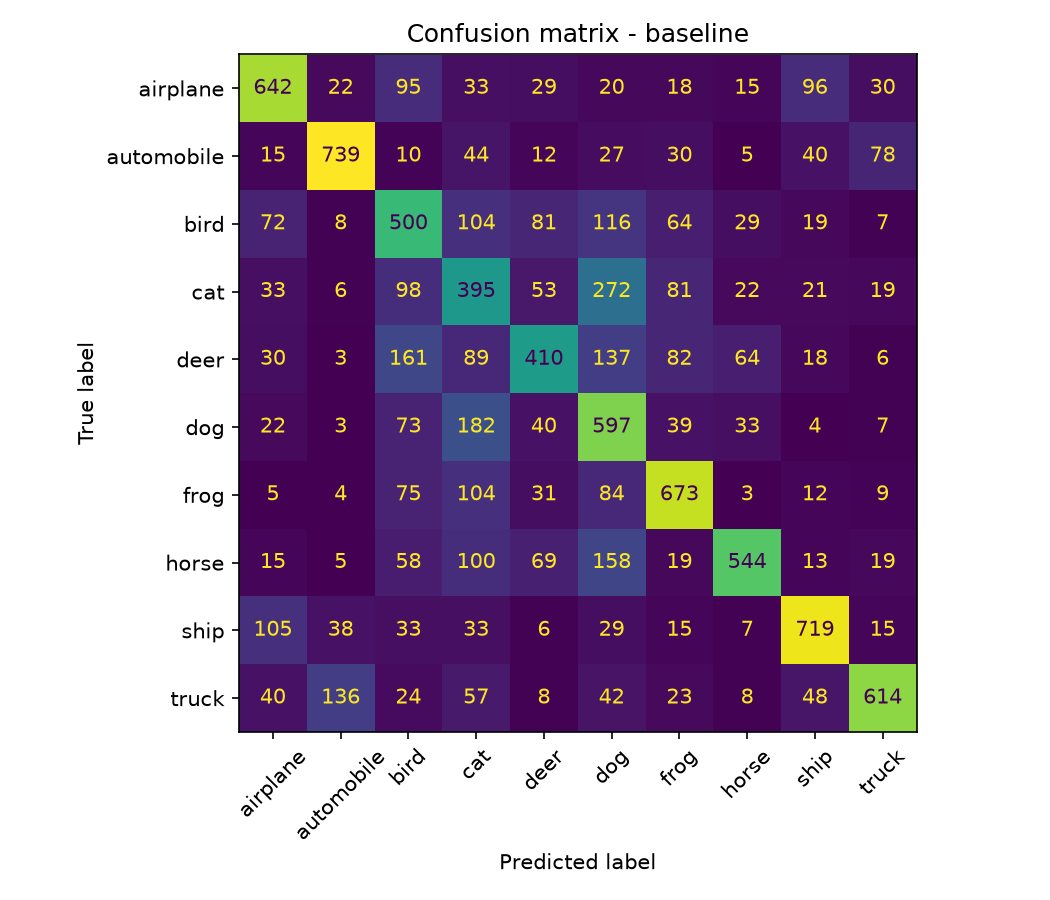

Best tuned confusion matrix


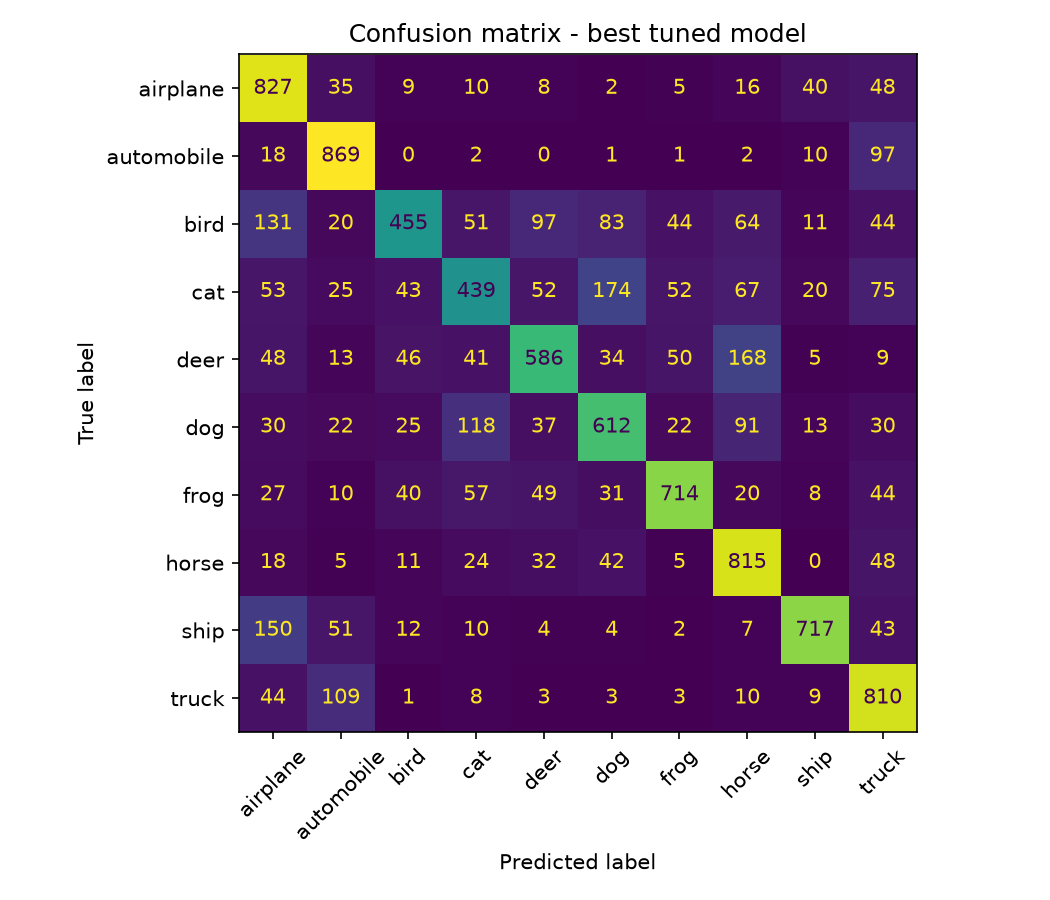

In [8]:
def retrain_for_confusion(dataset, outdir):
    from tensorflow import keras

    rs = read_json("random_search.json")
    cfg = rs["best_config"]
    print("Best tuned config from random_search.json:", cfg)

    outdir = Path(outdir)
    exact_dir = outdir / "exact"
    exact_dir.mkdir(parents=True, exist_ok=True)

    # baseline: identical to q2_cnn.py (seed, no dropout, no augmentation, original epochs/batch)
    set_seed()
    m = build_cnn(dropout=0.0, augment=False)
    fit(m, dataset, EPOCHS_BASE, BATCH_BASE)
    met, y_base = evaluate_test(m, dataset)
    print("baseline test:", met)
    np.save(str(exact_dir / "y_pred_baseline.npy"), y_base)
    m.save(str(exact_dir / "model_baseline.keras"))

    # tuned: identical to the best trial in q2_random_search.py (early stopping on val_loss)
    set_seed()
    m = build_cnn(lr=cfg["lr"], dropout=cfg["dropout"], dense_units=cfg["dense_units"],
                  filters=tuple(cfg["filters"]), augment=cfg["augment"])
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                       restore_best_weights=True)
    fit(m, dataset, EPOCHS_TUNED, cfg["batch"], [es])
    met, y_tuned = evaluate_test(m, dataset)
    print("tuned test:", met)
    np.save(str(exact_dir / "y_pred_tuned.npy"), y_tuned)
    m.save(str(exact_dir / "model_tuned.keras"))
    np.save(str(exact_dir / "y_test.npy"), dataset["y_test"])


def exact_dir_path():
    preferred = OUTPUT_DIR / "exact"
    if (preferred / "y_test.npy").exists():
        return preferred
    fallback = RESULTS / "exact"
    if (fallback / "y_test.npy").exists():
        return fallback
    return preferred


if RUN_CONFUSION_REPRO:
    retrain_for_confusion(data, RESULTS_NB)

exact_dir = exact_dir_path()
y_test_saved = np.load(str(exact_dir / "y_test.npy"))
preds = {k: np.load(str(exact_dir / f"y_pred_{k}.npy")) for k in ["baseline", "tuned"]}
refs = {
    "baseline": read_json("results.json")["baseline"]["test_acc"],
    "tuned": read_json("random_search.json")["test_acc"],
}
text, analysis = build_report(y_test_saved, preds, refs)
if RUN_CONFUSION_REPRO:
    write_report(y_test_saved, preds, exact_dir, refs)

display(Markdown(text))
for k in preds:
    diff = float((preds[k] == y_test_saved).mean()) - refs[k]
    status = ("REPRODUCED (identical)" if abs(diff) < 1e-4
              else f"DIFFERS from original by {diff:+.4f}")
    print(f"[check] {k}: {status}")

show_image("confusion_baseline.png", "Baseline confusion matrix")
show_image("confusion_tuned.png", "Best tuned confusion matrix")


## 7. Extension — random search with early stopping

The search space, generator seed, validation-only model selection, and early-stopping callback are copied from `q2_random_search.py`. With the switch off, the top trials and best-trial test metrics are read from the saved random-search artifact; with it on, the search is rerun and written only to `results_nb/`.


In [9]:
def run_random_search(dataset, outdir, trials=N_TRIALS, epochs=EPOCHS_TUNED):
    from tensorflow import keras

    outdir = Path(outdir)
    outdir.mkdir(parents=True, exist_ok=True)

    rng = np.random.default_rng(0)
    trial_records, best = [], {"val": -1}

    for t in range(trials):
        cfg = dict(lr=float(10 ** rng.uniform(-4, np.log10(3e-3))),
                   dropout=float(rng.choice([0.2, 0.3, 0.4, 0.5])),
                   dense_units=int(rng.choice([128, 256, 512])),
                   filters=[(32, 64, 128), (64, 128, 256)][int(rng.integers(2))],
                   augment=True)
        batch = int(rng.choice([32, 64, 128]))
        print(f"\n=== trial {t + 1}/{trials}: {cfg}, batch={batch} ===")
        set_seed()
        model = build_cnn(**cfg)
        es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                           restore_best_weights=True)
        hist = fit(model, dataset, epochs, batch, callbacks=[es])
        s = summarize_history(hist)
        val_acc = float(model.evaluate(dataset["x_val"], dataset["y_val"], verbose=0)[1])
        trial_records.append({**cfg, "filters": list(cfg["filters"]), "batch": batch,
                              "epochs_run": s["epochs_run"], "val_acc": val_acc})
        if val_acc > best["val"]:
            best = {"val": val_acc, "cfg": trial_records[-1],
                    "model": model, "hist": hist.history}

    test_metrics, y_pred = evaluate_test(best["model"], dataset)
    plot_confusion(dataset["y_test"], y_pred, "Confusion matrix - best tuned model",
                   str(outdir / "confusion_tuned.png"))
    plot_curves({"tuned": best["hist"]}, str(outdir / "curves_tuned.png"))

    base_path = outdir / "results.json"
    if not base_path.exists():
        base_path = RESULTS / "results.json"
    base = json.loads(base_path.read_text(encoding="utf-8")) if base_path.exists() else {}
    out = {"trials": sorted(trial_records, key=lambda r: -r["val_acc"]),
           "best_config": best["cfg"], "best_val_acc": best["val"], **test_metrics,
           "reference_test_acc": {k: v["test_acc"] for k, v in base.items()}}
    save_json(out, str(outdir / "random_search.json"))
    return out


Top trials by val acc:
{'lr': 0.0001526094648129323, 'dropout': 0.2, 'dense_units': 512, 'filters': [64, 128, 256], 'augment': True, 'batch': 64, 'epochs_run': 30, 'val_acc': 0.6832000017166138}
{'lr': 0.0008109581224658478, 'dropout': 0.5, 'dense_units': 256, 'filters': [32, 64, 128], 'augment': True, 'batch': 128, 'epochs_run': 30, 'val_acc': 0.6474000215530396}
{'lr': 0.0002771473968728251, 'dropout': 0.3, 'dense_units': 256, 'filters': [32, 64, 128], 'augment': True, 'batch': 32, 'epochs_run': 22, 'val_acc': 0.6370000243186951}
{'lr': 0.0001817459118418355, 'dropout': 0.2, 'dense_units': 512, 'filters': [32, 64, 128], 'augment': True, 'batch': 64, 'epochs_run': 30, 'val_acc': 0.6269999742507935}
{'lr': 0.00010578237701278464, 'dropout': 0.2, 'dense_units': 512, 'filters': [64, 128, 256], 'augment': True, 'batch': 128, 'epochs_run': 30, 'val_acc': 0.6179999709129333}

Best: {'lr': 0.0001526094648129323, 'dropout': 0.2, 'dense_units': 512, 'filters': [64, 128, 256], 'augment': True, 

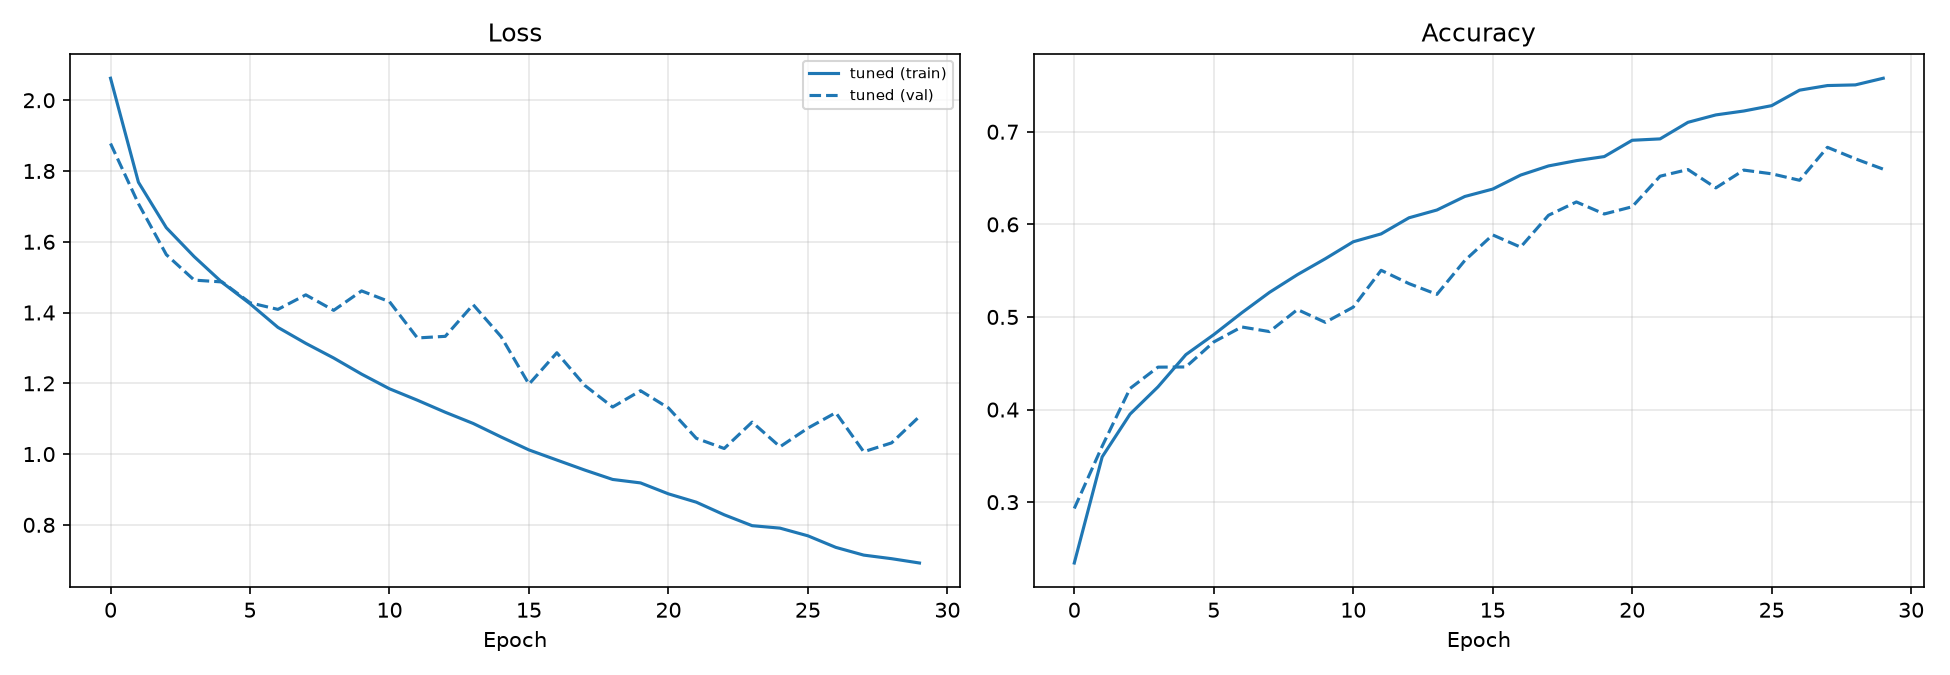

In [10]:
if RUN_RANDOM_SEARCH:
    search_results = run_random_search(data, RESULTS_NB)
else:
    search_results = read_json("random_search.json")

print("Top trials by val acc:")
for r in search_results["trials"][:5]:
    print(r)
print("\nBest:", search_results["best_config"])
print("Best val acc:", search_results["best_val_acc"])
print("TEST:", {"test_loss": search_results["test_loss"],
                "test_acc": search_results["test_acc"]})
print("Tuned test accuracy (4 decimals): %.4f" % search_results["test_acc"])
print("\nReference test accuracies:")
for k, v in search_results["reference_test_acc"].items():
    print(f"  reference {k:14s} test_acc = {v:.4f}")

show_image("curves_tuned.png", "Best tuned model learning curves")


## 8. Comparison and reproducibility note

The table combines the four base configurations with the best random-search trial. Every value is read from the JSON artifacts or recomputed from saved predictions above.


In [11]:
comparison_rows = []
for name, r in base_results.items():
    comparison_rows.append({
        "model": name,
        "dropout": r["dropout"],
        "augment": r["augment"],
        "val_acc": r["final_val_acc"],
        "test_acc": r["test_acc"],
        "test_loss": r["test_loss"],
    })
comparison_rows.append({
    "model": "tuned (random search)",
    "dropout": search_results["best_config"]["dropout"],
    "augment": search_results["best_config"]["augment"],
    "val_acc": search_results["best_val_acc"],
    "test_acc": search_results["test_acc"],
    "test_loss": search_results["test_loss"],
})

header = ("%-22s %7s %7s %9s %9s %9s"
          % ("model", "dropout", "augment", "val_acc", "test_acc", "test_loss"))
print(header)
print("-" * len(header))
for row in comparison_rows:
    print("%-22s %7.1f %7s %9.4f %9.4f %9.4f"
          % (row["model"], row["dropout"], str(row["augment"]),
             row["val_acc"], row["test_acc"], row["test_loss"]))


model                  dropout augment   val_acc  test_acc test_loss
--------------------------------------------------------------------
baseline                   0.0   False    0.5838    0.5833    3.6184
dropout                    0.4   False    0.6620    0.6766    1.4088
augmentation               0.0    True    0.6848    0.6888    1.1285
dropout+aug                0.4    True    0.6616    0.6697    1.0376
tuned (random search)      0.2    True    0.6832    0.6844    0.9926


In [12]:
analysis_json_path = artifact_path("exact/confusion_analysis.json")
if analysis_json_path.is_file():
    exact_saved = json.loads(analysis_json_path.read_text(encoding="utf-8"))
else:
    exact_saved = {
        "baseline": {"accuracy": analysis["baseline"]["accuracy"]},
        "tuned": {"accuracy": analysis["tuned"]["accuracy"]},
    }

baseline_original = base_results["baseline"]["test_acc"]
baseline_repeat = exact_saved["baseline"]["accuracy"]
tuned_original = search_results["test_acc"]
tuned_repeat = exact_saved["tuned"]["accuracy"]
diff_pp = 100.0 * (baseline_repeat - baseline_original)

note = (
    f"Reproducibility note: two otherwise identical baseline runs gave "
    f"{baseline_original:.4f} and {baseline_repeat:.4f} test accuracy "
    f"(a difference of {abs(diff_pp):.1f} percentage points). Differences of about two "
    f"points are within run-to-run variation. The tuned run was reproduced from saved "
    f"predictions: {tuned_original:.4f} in random_search.json and {tuned_repeat:.4f} "
    f"recomputed from the saved test predictions."
)
display(Markdown(note))


Reproducibility note: two otherwise identical baseline runs gave 0.5833 and 0.5998 test accuracy (a difference of 1.7 percentage points). Differences of about two points are within run-to-run variation. The tuned run was reproduced from saved predictions: 0.6844 in random_search.json and 0.6844 recomputed from the saved test predictions.